# Лабораторна робота №1
## Базові алгоритми класифікації у Scikit-learn
Студент: Мельник Владислав

Група: ФБ-61мп

Датасет: TON-IoT Network Dataset



# 1. Мета роботи
Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.

# 2. Вибір датасета
Для виконання лабораторної роботи було обрано TON_IoT Network Dataset з платформи Kaggle. Датасет містить мережевий трафік IoT та IIoT середовища та використовується для задач класифікації мережевих атак.
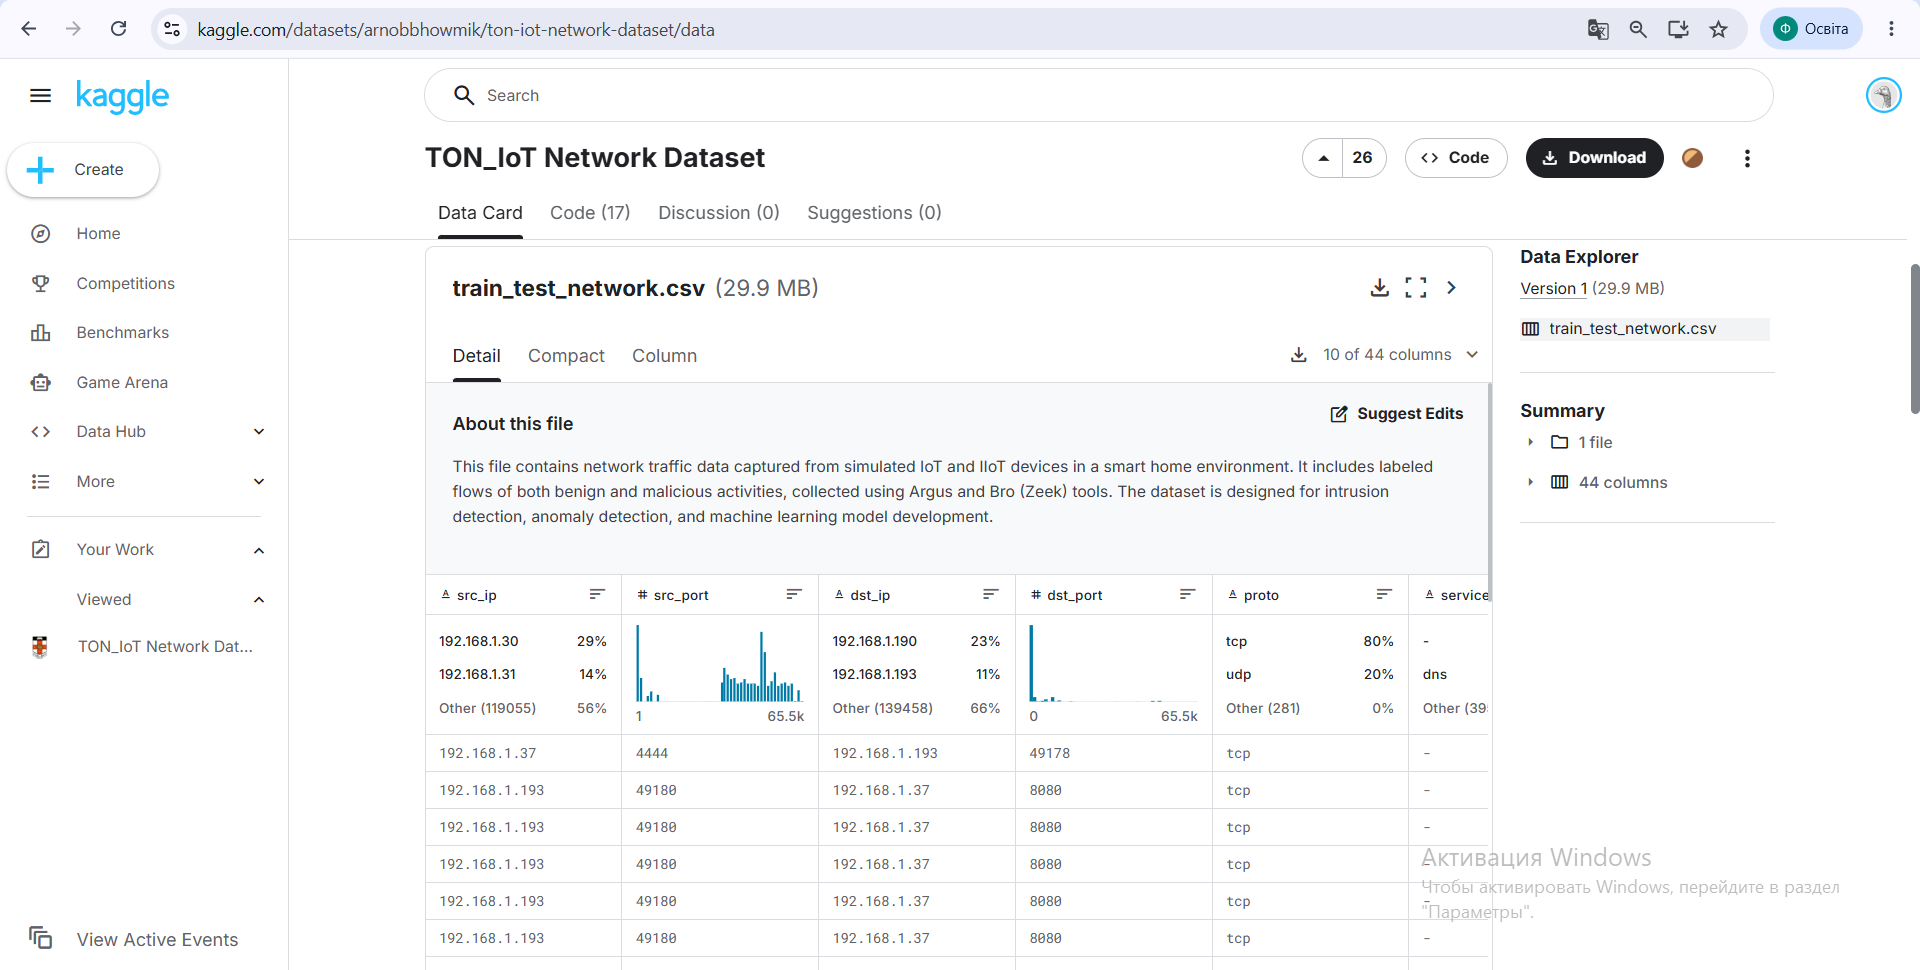


# 3. Первинний аналіз даних
Датасет містить 211043 об'єкти та 44 ознаки.

Проаналізовано структуру набору даних та типи змінних.


In [13]:
import pandas as pd
df = pd.read_csv("/train_test_network.csv")
print(df.shape)
df.info()
df.columns

(211043, 44)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_

Index(['src_ip', 'src_port', 'dst_ip', 'dst_port', 'proto', 'service',
       'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes',
       'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query',
       'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA',
       'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed',
       'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth',
       'http_method', 'http_uri', 'http_version', 'http_request_body_len',
       'http_response_body_len', 'http_status_code', 'http_user_agent',
       'http_orig_mime_types', 'http_resp_mime_types', 'weird_name',
       'weird_addl', 'weird_notice', 'label', 'type'],
      dtype='object')

Було переглянуто перші записи датасету.
Вибірка містить інформацію про мережевий трафік, включаючи IP-адреси, порти, протоколи, тривалість з'єднання та інші характеристики мережевих сесій.

In [14]:
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


## 3.1. Аналіз класів
За результатами аналізу встановлено, що цільова змінна label містить два класи: нормальний мережевий трафік та атаки.
Більшість записів належить до класу атак (161043 записів), тоді як нормальний трафік представлений 50000 записами.
Колонка type містить детальні категорії атак, такі як DDoS, DoS, Backdoor, Ransomware та інші.


In [15]:
df["label"].value_counts()

,count
label,
1,161043
0,50000


In [16]:
df["type"].value_counts()

,count
type,
normal,50000
backdoor,20000
ddos,20000
dos,20000
injection,20000
password,20000
scanning,20000
ransomware,20000
xss,20000


## 3.2. Перевірка пропусків
Виконано перевірку наявності пропущених значень у наборі даних.
У результаті перевірки встановлено, що пропущені значення в датасеті відсутні. Додаткова обробка пропусків не потрібна.

In [17]:
df.isnull().sum()

,0
src_ip,0
src_port,0
dst_ip,0
dst_port,0
proto,0
service,0
duration,0
src_bytes,0
dst_bytes,0
conn_state,0


In [18]:
df.select_dtypes(include="object").columns

Index(['src_ip', 'dst_ip', 'proto', 'service', 'conn_state', 'dns_query',
       'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version',
       'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject',
       'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri',
       'http_version', 'http_user_agent', 'http_orig_mime_types',
       'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice',
       'type'],
      dtype='object')

# 4. Візуалізація даних
## 4.1. Heatmap кореляцій числових ознак
На тепловій карті видно, що більшість ознак мають слабку або помірну кореляцію між собою. Разом із тим спостерігаються окремі групи ознак із сильним позитивним зв'язком, особливо серед DNS-, HTTP- та SSL-характеристик. Це свідчить про наявність взаємопов'язаних параметрів мережевого трафіку.

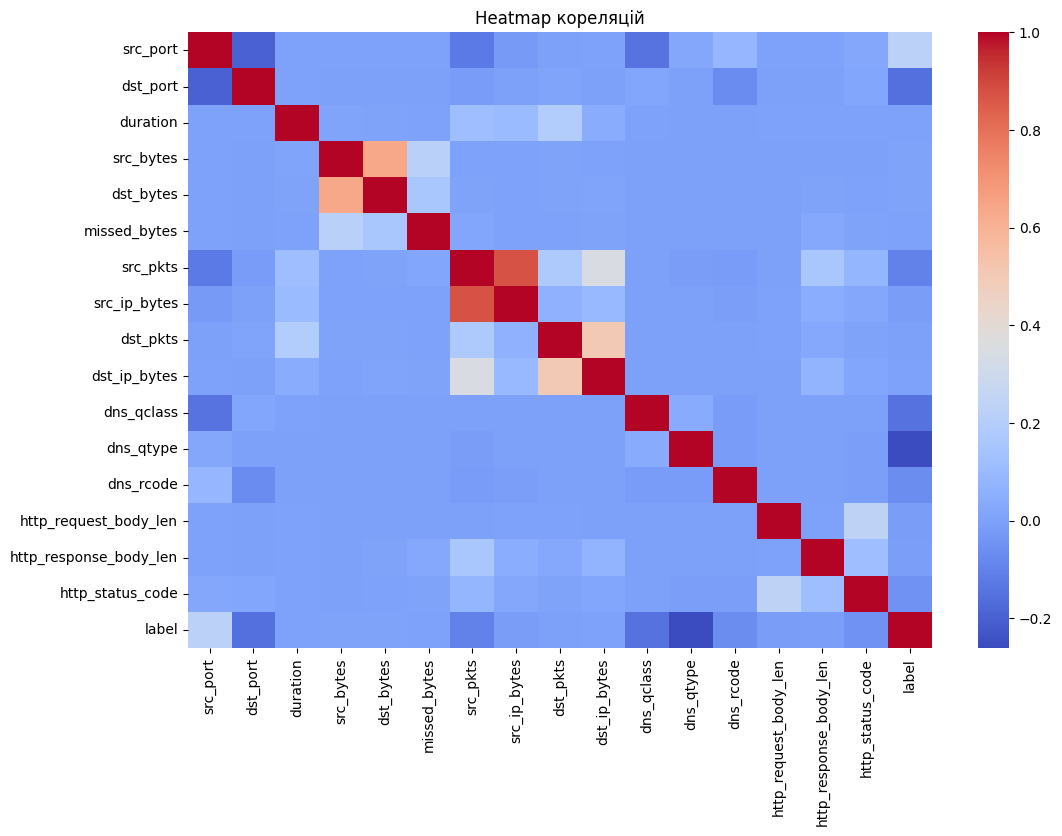

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    cmap='coolwarm'
)

plt.title("Heatmap кореляцій")

plt.show()

## 4.2. Гістограми розподілу ознак
Гістограми показують, що більшість досліджуваних ознак мають нерівномірний розподіл. Основна кількість спостережень зосереджена в області малих значень, тоді як окремі записи мають дуже великі значення. Такий розподіл є типовим для даних мережевого трафіку та може бути пов'язаний із різними типами мережевої активності.

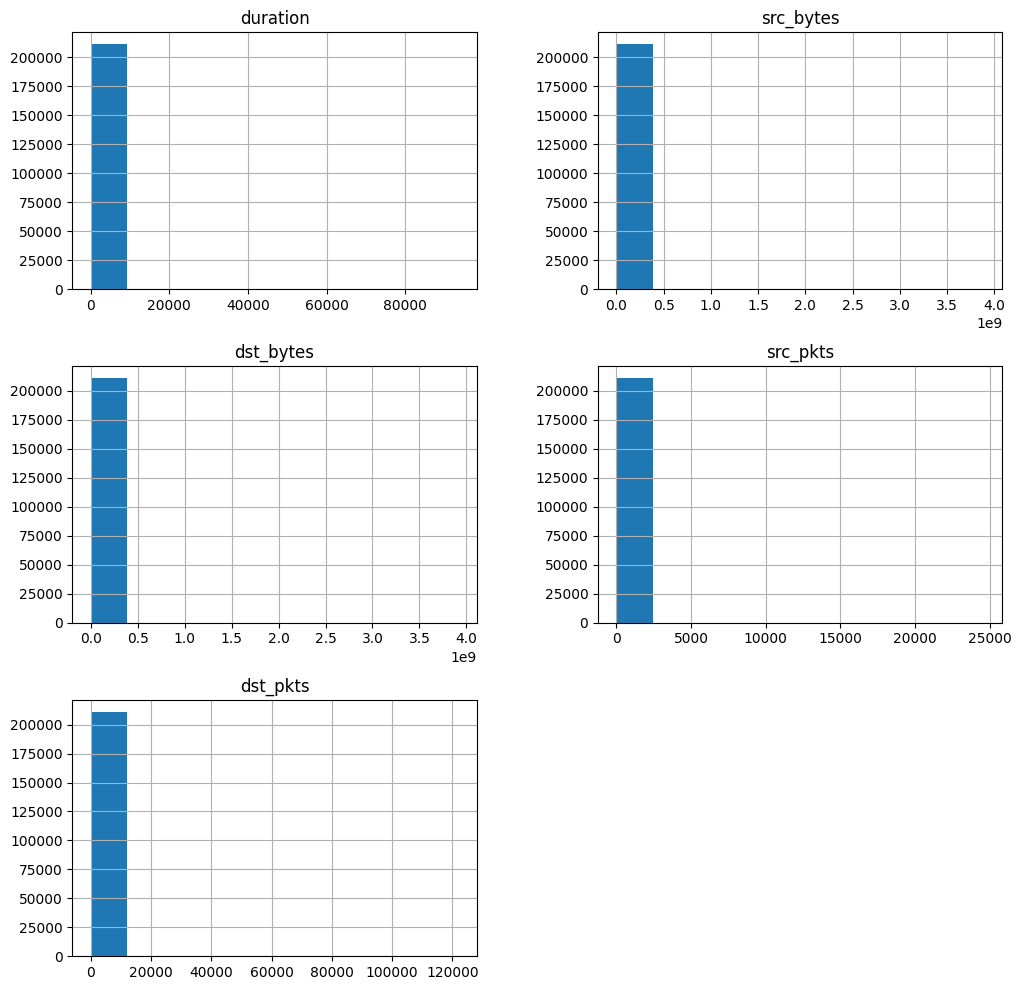

In [20]:
df[
    [
       "duration",
       "src_bytes",
       "dst_bytes",
       "src_pkts",
       "dst_pkts"
    ]
].hist(figsize=(12,12))

plt.show()

## 4.3. Boxplot відносно цільової змінної
Boxplot демонструє розподіл ознаки duration відносно цільової змінної label. Для обох класів більшість значень зосереджена поблизу нуля, проте спостерігаються окремі викиди з великими значеннями тривалості з'єднання. Для класу атак (label = 1) кількість та величина викидів дещо більша, що може свідчити про наявність тривалих мережевих сесій під час атак.

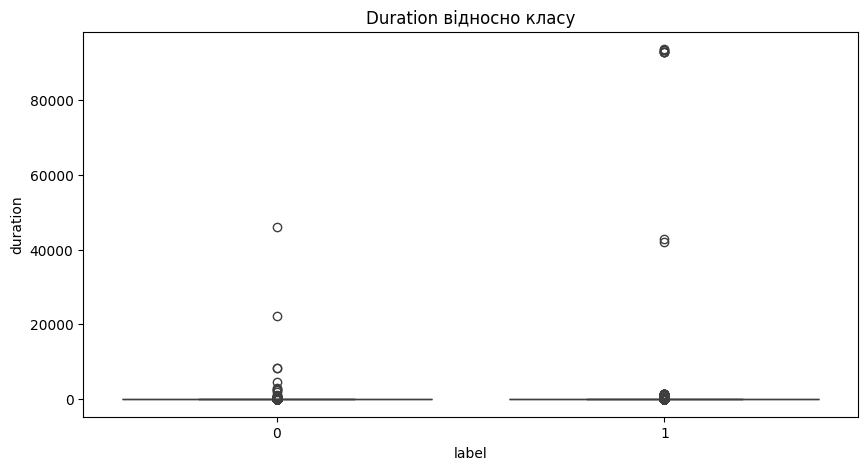

In [21]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=df["label"],
    y=df["duration"]
)

plt.title("Duration відносно класу")

plt.show()

# 5. Підготовка даних до навчання моделей
Категоріальні ознаки були закодовані за допомогою LabelEncoder для подальшого використання алгоритмів машинного навчання. Пропущених значень у наборі не виявилося, тому додаткова обробка пропусків не проводилася.

In [22]:
from sklearn.preprocessing import LabelEncoder
df_encoded = df.copy()
for col in df_encoded.select_dtypes(include="object").columns:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(
        df_encoded[col].astype(str)
    )
print("Кодування завершено")

Кодування завершено


Для задачі класифікації було обрано цільову змінну label, яка містить два класи: нормальний трафік та атаки. Як ознаки (features) використовувалися всі інші характеристики мережевого трафіку за винятком колонок label та type.

In [23]:
X = df_encoded.drop(["label", "type"], axis=1)

y = df_encoded["label"]

print(X.shape)
print(y.shape)

(211043, 42)
(211043,)


Для задачі класифікації було сформовано матрицю ознак X розміром (211043, 42) та цільову змінну y розміром 211043 записів.

Набір даних було поділено на навчальну та тестову вибірки у співвідношенні 80% до 20%.

Розмір навчальної вибірки становить 168834 об'єкти, а тестової — 42209 об'єктів.

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)

(168834, 42)
(42209, 42)


# 6. Масштабування даних
Для алгоритмів kNN та SVM було виконано масштабування ознак за допомогою StandardScaler, що дозволяє уникнути впливу різних масштабів ознак на результати класифікації.

In [25]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(168834, 42)
(42209, 42)


# 7. Навчання моделі kNN
Навчено модель k-найближчих сусідів та визначено її точність.

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("Accuracy:", accuracy_knn)

Accuracy: 0.9990760264398588


## 7.1. Classification Report для kNN
За результатами навчання моделі kNN було отримано точність 99.91%. Показники Precision, Recall та F1-score для обох класів наближаються до 1, що свідчить про високу якість класифікації мережевого трафіку.

In [27]:
from sklearn.metrics import classification_report
print("kNN")
print(classification_report(y_test, y_pred_knn))

kNN
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



## 7.2. Confusion Matrix для kNN
Матриця помилок демонструє кількість правильних та неправильних класифікацій моделі kNN. Вона показує, що модель kNN правильно класифікує переважну більшість записів. Кількість помилково класифікованих об'єктів є незначною.

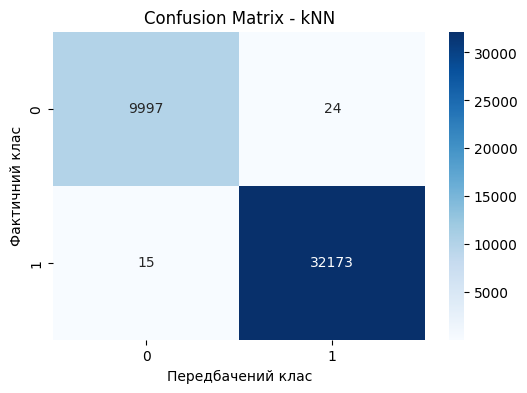

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Передбачений клас")
plt.ylabel("Фактичний клас")
plt.title("Confusion Matrix - kNN")

plt.show()

## 7.3. Підбір параметра k
Досліджено вплив параметра k на точність класифікації

In [29]:
scores = []

for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)

    scores.append(
      accuracy_score(y_test, pred)
    )

За результатами підбору параметра k встановлено, що найвища точність досягається при малих значеннях k. Із збільшенням кількості сусідів точність моделі поступово зменшується.

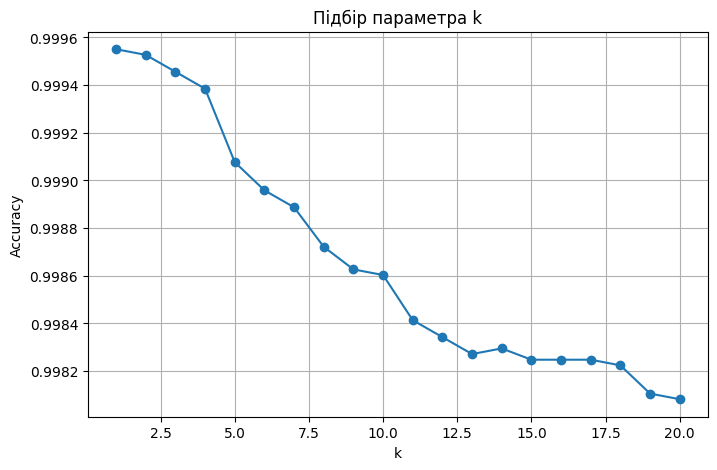

In [30]:
plt.figure(figsize=(8,5))
plt.plot(range(1,21), scores, marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Підбір параметра k")
plt.grid(True)
plt.show()

# 8. Навчання інших моделей класифікації
## 8.1. Decision Tree

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print("Decision Tree Accuracy:", accuracy_dt)

Decision Tree Accuracy: 0.9999526167405056


### 8.1.1. Classification Report

In [32]:
from sklearn.metrics import classification_report
print("Decision Tree")
print(classification_report(y_test, y_pred_dt))

Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



### 8.1.2. Confusion Matrix

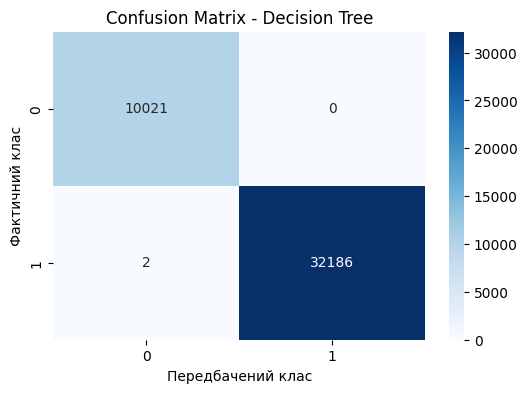

In [33]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6,4))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Передбачений клас")
plt.ylabel("Фактичний клас")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

## 8.2. Random Forest

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.9999763083702528


### 8.2.1. Classification Report

In [35]:
from sklearn.metrics import classification_report
print("Random Forest")
print(classification_report(y_test, y_pred_rf))

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



### 8.2.2. Сonfusion Matrix

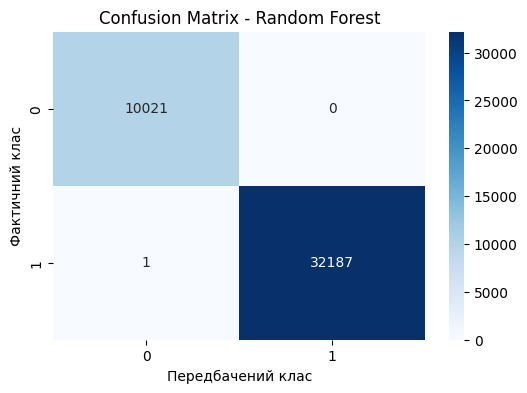

In [36]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Передбачений клас")
plt.ylabel("Фактичний клас")
plt.title("Confusion Matrix - Random Forest")

plt.show()

## 8.3. AdaBoost

In [37]:
from sklearn.ensemble import AdaBoostClassifier

ab = AdaBoostClassifier(
    random_state=42
)

ab.fit(X_train, y_train)

y_pred_ab = ab.predict(X_test)

accuracy_ab = accuracy_score(
    y_test,
    y_pred_ab
)

print("AdaBoost Accuracy:", accuracy_ab)

AdaBoost Accuracy: 0.9997630837025279


### 8.3.1. Classification Report

In [38]:
from sklearn.metrics import classification_report
print("AdaBoost")
print(classification_report(y_test, y_pred_ab))

AdaBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



### 8.3.2. Confusion Matrix

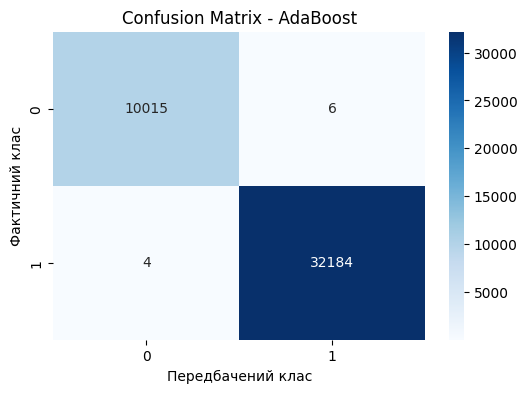

In [39]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_ab = confusion_matrix(y_test, y_pred_ab)

plt.figure(figsize=(6,4))
sns.heatmap(cm_ab, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Передбачений клас")
plt.ylabel("Фактичний клас")
plt.title("Confusion Matrix - AdaBoost")
plt.show()

## 8.4. SVM
Для навчання моделі SVM використано підмножину навчальної вибірки обсягом 20000 записів. Таке рішення дозволило скоротити час навчання моделі, оскільки алгоритм SVM є ресурсоємним при роботі з великими наборами даних.

In [40]:
X_train_svm = X_train_scaled[:20000]
y_train_svm = y_train[:20000]

In [41]:
from sklearn.svm import SVC

svm = SVC()

svm.fit(
    X_train_svm,
    y_train_svm
)

y_pred_svm = svm.predict(
    X_test_scaled
)

accuracy_svm = accuracy_score(
    y_test,
    y_pred_svm
)

print("SVM Accuracy:", accuracy_svm)

SVM Accuracy: 0.9939349427847142


### 8.4.1. Сlassification Report

In [42]:
from sklearn.metrics import classification_report
print("SVM")
print(classification_report(y_test, y_pred_svm))

SVM
              precision    recall  f1-score   support

           0       0.98      0.99      0.99     10021
           1       1.00      0.99      1.00     32188

    accuracy                           0.99     42209
   macro avg       0.99      0.99      0.99     42209
weighted avg       0.99      0.99      0.99     42209



### 8.4.2. Confusion Matrix

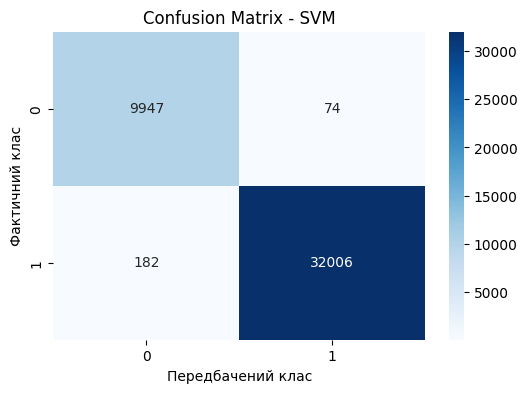

In [43]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6,4))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Передбачений клас")
plt.ylabel("Фактичний клас")
plt.title("Confusion Matrix - SVM")
plt.show()

# 9. Підбір гіперпараметрів SVM
## 9.1. Найкращі параметри SVM
У результаті підбору параметрів найкращими виявилися C = 10 та gamma = 0,1. Такі значення дали найкращий результат серед перевірених комбінацій
## 9.2. Найкращий результат крос-валідації
Найкращий результат крос-валідації становить близько 99,8%. Це свідчить про те, що підібрана комбінація параметрів добре працює на навчальних даних під час перевірки.

In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [1, 0.1, 0.01]
}

grid = GridSearchCV(
    SVC(),
    param_grid,
    cv=3,
    n_jobs=-1
)

grid.fit(
    X_train_scaled[:10000],
    y_train[:10000]
)

print("Найкращі параметри:", grid.best_params_)
print("Найкращий результат:", grid.best_score_)

Найкращі параметри: {'C': 10, 'gamma': 0.1}
Найкращий результат: 0.9975999999520049


## 9.3. Accuracy після підбору параметрів
Після використання підібраних параметрів точність моделі SVM на тестових даних становить приблизно 99,75%. Це дуже високий результат, тому можна сказати, що модель добре класифікує тестові дані.

In [47]:
best_svm = grid.best_estimator_

y_pred_best_svm = best_svm.predict(X_test_scaled)

best_svm_accuracy = accuracy_score(
    y_test,
    y_pred_best_svm
)

print("Accuracy SVM після підбору параметрів:", best_svm_accuracy)

Accuracy SVM після підбору параметрів: 0.9974886872467957


## 9.4. Classification Report
Модель добре розпізнає обидва класи. Для класу 0 показники також дуже високі, а для класу 1 precision, recall та f1-score дорівнюють 1.00.

In [51]:
print("Classification Report для SVM після підбору параметрів:\n")
print(classification_report(y_test, y_pred_best_svm))

Classification Report для SVM після підбору параметрів:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



# 10. Аналіз Classification Report для моделей
Для моделей kNN, Decision Tree, Random Forest та AdaBoost показники Precision, Recall та F1-score наближаються до 1.00, що свідчить про дуже високу якість класифікації. Найкращий результат продемонструвала модель Random Forest. Модель SVM після підбору параметрів також показала дуже високі результати, хоча її точність дещо нижча порівняно з іншими моделями.

# 11. Аналіз Confusion Matrix моделей
Матриці помилок показують, що всі досліджені моделі правильно класифікують переважну більшість об'єктів. Найменшу кількість помилок продемонструвала модель Random Forest. Decision Tree та AdaBoost також показали дуже високу якість класифікації. SVM також правильно класифікує більшість об'єктів, хоча кількість помилок у неї дещо більша.

# 12. Порівняння моделей
За результатами порівняння моделей встановлено, що найкращу точність продемонструвала модель Random Forest (99.9976%). Дещо нижчі, але також дуже високі результати показали Decision Tree, AdaBoost та kNN. Після підбору параметрів точність моделі SVM становила приблизно 99.75%, що також є дуже високим результатом.

Таблиця результатів

In [52]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
       "kNN",
       "Decision Tree",
       "Random Forest",
       "AdaBoost",
       "SVM"
    ],
    "Accuracy": [
       accuracy_knn,
       accuracy_dt,
       accuracy_rf,
       accuracy_ab,
       best_svm_accuracy
    ]
})

results

,Model,Accuracy
0,kNN,0.999076
1,Decision Tree,0.999953
2,Random Forest,0.999976
3,AdaBoost,0.999763
4,SVM,0.997489


# Висновки
Під час виконання лабораторної роботи проведено дослідження TON-IoT Network Dataset.
Виконано первинний аналіз даних, попередню обробку, візуалізацію ознак та навчання п'яти моделей класифікації: kNN, Decision Tree, SVM, Random Forest та AdaBoost.
Для моделей проведено оцінювання за допомогою Accuracy, Classification Report та Confusion Matrix. Для SVM додатково проведено підбір гіперпараметрів C та gamma за допомогою GridSearchCV, після чого точність моделі склала приблизно 99.75%. Найкращий результат продемонструвала модель Random Forest з точністю 99.9976%.
На мою думку, така модель найкраще підходить для аналізу мережевого трафіку, оскільки поєднання декількох дерев рішень дозволяє ефективно працювати з великою кількістю ознак та виявляти складні закономірності в даних.
Отримані результати підтверджують ефективність методів машинного навчання для задач виявлення мережевих атак в IoT-середовищах.